<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw12/HW12_GPTQ_Distillation_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 12: LLM Compression with GPTQ & Knowledge Distillation


## Step 0: Configuration
Follow the Step 0 instructions from Assignment 1. Fill in **SEED**, **HP_ID**, and the instructor-provided base LLM.
All later cells read these values; nothing else needs to change.

In [9]:
# ======================= EDIT ME =======================
STUDENT_NAME   = "Your Name"
SEED           = 30000           # <-- your SEED from Assignment 1 Step 0
HP_ID          = 0             # <-- your HP_ID from Assignment 1 Step 0 (apply it as Assignment 1 instructs; it does NOT add a temperature)

# Part 1: instructor-provided / approved base LLM. Do not change between the base and GPTQ runs.
BASE_MODEL_ID  = "facebook/opt-125m"   # <-- replace with the instructor-provided model ID
BASE_REVISION  = "main"                # pinned to an exact commit SHA automatically below

# Part 2: teacher folder (download the Canvas `teacher_model` folder to your Drive)
TEACHER_DIR    = "/content/drive/MyDrive/DATA266/teacher_model"
STUDENT_ID     = "distilbert-base-uncased"

# Distillation training settings (held fixed across every sweep run)
MAX_LEN        = 128
TRAIN_BS       = 32
EVAL_BS        = 128
LR             = 5e-5
WEIGHT_DECAY   = 0.01
EPOCHS         = 1
WARMUP_FRAC    = 0.06
TRAIN_SUBSET   = None   # None = all 120k AG News training samples. Set e.g. 30000 if you run short on GPU time
                        # (teacher logits are still extracted for ALL training samples).
KD_T2_SCALING  = True   # multiply KL term by T^2 (Hinton et al.) so gradient scale is comparable across T

TEMPERATURES   = [1, 2, 5, 10]
ALPHA_SWEEP_T  = 0.5
ALPHAS         = [0.25, 0.5, 0.75]

WORK_DIR       = "/content/hw12"
# =======================================================

In [2]:
# Pin Colab's preinstalled torch / torchvision / torchaudio so gptqmodel can't swap torch for a build
# compiled against a different CUDA version (that breaks `import transformers` with a TorchAudio CUDA mismatch).
!pip freeze | grep -E "^(torch|torchvision|torchaudio)==" > /content/torch_constraints.txt
!cat /content/torch_constraints.txt
!pip -q install -U -c /content/torch_constraints.txt "transformers>=4.45" accelerate datasets optimum evaluate tabulate
# GPTQ backend. gptqmodel is the maintained backend for transformers' GPTQConfig.
!pip -q install -c /content/torch_constraints.txt gptqmodel --no-build-isolation
# If gptqmodel REQUIRES a newer torch and the line above fails, install it without -c and then run:
#   !pip uninstall -y torchaudio      # unused here; removing it avoids the CUDA-mismatch import error
# Afterwards: Runtime > Restart session, then continue from the next cell (don't re-run this one).

torch==2.14.1+cu130
torchaudio==2.11.0+cu130
torchvision==0.29.1+cu130


In [3]:
import os, gc, json, time, math, random, platform
from pathlib import Path
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import set_seed

os.makedirs(WORK_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", "GPTQ and the latency/memory measurements need a GPU runtime."

def seed_everything(s):
    set_seed(s); random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

HARDWARE = {
    "gpu": torch.cuda.get_device_name(0),
    "gpu_mem_GB": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1),
    "torch": torch.__version__, "transformers": transformers.__version__,
    "cuda": torch.version.cuda, "python": platform.python_version(),
}
print(json.dumps(HARDWARE, indent=2))

def free_gpu():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.synchronize()

def dir_size_mb(path, weights_only=True):
    exts = (".safetensors", ".bin", ".pt") if weights_only else None
    total = 0
    for p in Path(path).rglob("*"):
        if p.is_file() and (exts is None or p.suffix in exts):
            total += p.stat().st_size
    return total / 2**20

def pctl(xs):
    xs = np.asarray(xs)
    return float(np.percentile(xs, 50)), float(np.percentile(xs, 95))

W1124 21:33:47.364000 3665 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 21:33:47.501000 3665 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


{
  "gpu": "Tesla T4",
  "gpu_mem_GB": 15.6,
  "torch": "2.14.1+cu130",
  "transformers": "5.24.1",
  "cuda": "13.0",
  "python": "3.13.16"
}


In [4]:
from huggingface_hub import model_info
from transformers import AutoTokenizer, AutoModelForCausalLM, GPTQConfig
from datasets import load_dataset

info = model_info(BASE_MODEL_ID, revision=BASE_REVISION)
BASE_SHA = info.sha
print(f"Base model : {BASE_MODEL_ID}\nRevision   : {BASE_SHA}")

PPL_STRIDE, N_LAT, PROMPT_TOKENS, NEW_TOKENS = 512, 50, 128, 32
BASE_DIR  = f"{WORK_DIR}/base_fp16"
GPTQ_DIR  = f"{WORK_DIR}/gptq_4bit"

tok = AutoTokenizer.from_pretrained(BASE_MODEL_ID, revision=BASE_SHA)
if tok.pad_token is None: tok.pad_token = tok.eos_token

# Wikitext-2: test split for perplexity, train split for the fixed latency prompt
wiki_test  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
wiki_train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")

test_ids = tok("\n\n".join(wiki_test["text"]), return_tensors="pt").input_ids
print("Wikitext-2 test tokens:", test_ids.shape[1])

# Fixed latency prompt (identical for both models)
_long = " ".join(t for t in wiki_train["text"][:400] if t.strip())
LAT_PROMPT_IDS = tok(_long, return_tensors="pt").input_ids[:, :PROMPT_TOKENS]
print("Latency prompt tokens:", LAT_PROMPT_IDS.shape[1])

Base model : facebook/opt-125m
Revision   : 27dcfa74d334bc871f3234de431e71c6eeba5dd6


Wikitext-2 test tokens: 287645
Latency prompt tokens: 128


In [5]:
@torch.no_grad()
def wikitext_ppl(model, max_len, stride=PPL_STRIDE):
    model.eval(); nlls, n_tok, prev_end = [], 0, 0
    seq_len = test_ids.size(1)
    for begin in range(0, seq_len, stride):
        end = min(begin + max_len, seq_len); trg_len = end - prev_end
        ids = test_ids[:, begin:end].to(DEVICE)
        labels = ids.clone(); labels[:, :-trg_len] = -100
        loss = model(ids, labels=labels).loss
        nlls.append(loss.float() * trg_len); n_tok += trg_len; prev_end = end
        if end == seq_len: break
    return math.exp(torch.stack(nlls).sum().item() / n_tok)

@torch.no_grad()
def gen_latency(model, n=N_LAT, warmup=5):
    ids = LAT_PROMPT_IDS.to(DEVICE); attn = torch.ones_like(ids)
    kw = dict(attention_mask=attn, max_new_tokens=NEW_TOKENS, min_new_tokens=NEW_TOKENS,
              do_sample=False, pad_token_id=tok.pad_token_id)
    for _ in range(warmup): model.generate(ids, **kw)
    times = []
    for _ in range(n):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        model.generate(ids, **kw)
        torch.cuda.synchronize(); times.append((time.perf_counter() - t0) * 1000)
    return times

def measure_llm(load_fn, label):
    free_gpu(); torch.cuda.reset_peak_memory_stats()
    model = load_fn(); model.eval()
    max_len = min(getattr(model.config, "max_position_embeddings", 2048), 2048)
    ppl = wikitext_ppl(model, max_len)
    lat = gen_latency(model)
    peak = torch.cuda.max_memory_allocated() / 1e9
    p50, p95 = pctl(lat)
    print(f"{label}: PPL={ppl:.3f}  p50={p50:.1f}ms  p95={p95:.1f}ms  peak={peak:.2f}GB")
    del model; free_gpu()
    return dict(ppl=ppl, p50=p50, p95=p95, peak_GB=peak, lat=lat, ppl_window=max_len)

### 1a. Base (unquantized, fp16) model

In [6]:
base = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, revision=BASE_SHA, torch_dtype=torch.float16)
base.save_pretrained(BASE_DIR, safe_serialization=True); tok.save_pretrained(BASE_DIR)
del base; free_gpu()

base_res = measure_llm(lambda: AutoModelForCausalLM.from_pretrained(BASE_DIR, torch_dtype=torch.float16).to(DEVICE), "Base fp16")
base_res["size_MB"] = dir_size_mb(BASE_DIR)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Base fp16: PPL=23.687  p50=436.2ms  p95=1157.9ms  peak=1.37GB


### 1b. Quantize with GPTQ (4-bit, Wikitext-2 calibration)

In [7]:
free_gpu(); seed_everything(SEED)
gptq_cfg = GPTQConfig(bits=4, group_size=128, dataset="wikitext2", tokenizer=tok, desc_act=False)
t0 = time.time()
qmodel = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, revision=BASE_SHA, torch_dtype=torch.float16,
                                              device_map="auto", quantization_config=gptq_cfg)
QUANT_TIME_S = time.time() - t0
print(f"Quantization took {QUANT_TIME_S/60:.1f} min")
qmodel.save_pretrained(GPTQ_DIR, safe_serialization=True); tok.save_pretrained(GPTQ_DIR)
del qmodel; free_gpu()


INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.10.0 Transformers : 5.24.1 Torch        : 2.14.1+cu130 Triton       : 3.8.0


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Quantizing model.decoder.layers blocks :   0%|          | 0/12 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

... (10 outputs left out)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3312: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


INFO  Extension load requested for `pack_block_cpu`: pack_block_cpu             


INFO  pack_block_cpu: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/pack_block_cpu/580832ec415c1d4e`.
INFO  pack_block_cpu: torch.ops JIT extension ready in 46s (estimated ~31s, +15s).
INFO  Extension load finished successfully: pack_block_cpu                      
INFO  Optimize: `TritonV2Linear` compilation triggered.                         
INFO  gc.collect() reclaimed 480 objects in 0.348s                              
Quantization took 1.6 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [11]:
# Marlin kernels don't build on this T4/CUDA setup, so use GPTQModel's pure-PyTorch backend (no compilation)
load_cfg = GPTQConfig(bits=4, backend="torch")
gptq_res = measure_llm(
    lambda: AutoModelForCausalLM.from_pretrained(GPTQ_DIR, device_map={"": 0}, quantization_config=load_cfg),
    "GPTQ 4-bit (torch backend)")
gptq_res["size_MB"] = dir_size_mb(GPTQ_DIR)
print(f"GPTQ size on disk: {gptq_res['size_MB']:.1f} MB")

INFO  Kernel: selected: `TorchLinear`                                           


/usr/local/lib/python3.13/dist-packages/transformers/quantizers/auto.py:279: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.However, loading attributes (e.g. ['backend', 'max_input_length']) will be overwritten with the one you passed to `from_pretrained`. The rest will be ignored.
  warnings.warn(warning_msg)


Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

INFO  Optimize: `TorchLinear` compilation triggered.                            
INFO  gc.collect() reclaimed 270 objects in 0.803s                              
GPTQ 4-bit (torch backend): PPL=27.718  p50=1082.8ms  p95=1386.9ms  peak=1.37GB
GPTQ size on disk: 119.3 MB


### 1c. Table HW11.1: GPTQ comparison on the same LLM/task

In [12]:
t1 = pd.DataFrame([
    {"Configuration": "Base LLM (fp16)", "Quality metric (Wikitext-2 PPL ↓)": base_res["ppl"],
     "p50 / p95 latency (ms)": f'{base_res["p50"]:.1f} / {base_res["p95"]:.1f}',
     "Peak memory (GB)": base_res["peak_GB"], "Size on disk (MB)": base_res["size_MB"]},
    {"Configuration": "GPTQ-quantized LLM (4-bit, g128)", "Quality metric (Wikitext-2 PPL ↓)": gptq_res["ppl"],
     "p50 / p95 latency (ms)": f'{gptq_res["p50"]:.1f} / {gptq_res["p95"]:.1f}',
     "Peak memory (GB)": gptq_res["peak_GB"], "Size on disk (MB)": gptq_res["size_MB"]},
])
print(f"Model: {BASE_MODEL_ID} @ {BASE_SHA} | GPU: {HARDWARE['gpu']} | latency = {PROMPT_TOKENS}-tok prompt → {NEW_TOKENS} new tokens, bs=1, n={N_LAT}")
print(t1.to_markdown(index=False, floatfmt=".2f"))
print(f"\nPPL change: {100*(gptq_res['ppl']/base_res['ppl']-1):+.2f}% | "
      f"p50 speed-up: {base_res['p50']/gptq_res['p50']:.2f}x | "
      f"memory: {gptq_res['peak_GB']/base_res['peak_GB']:.2f}x | disk: {gptq_res['size_MB']/base_res['size_MB']:.2f}x")
json.dump({"model": BASE_MODEL_ID, "sha": BASE_SHA, "hardware": HARDWARE,
           "base": {k: v for k, v in base_res.items() if k != "lat"},
           "gptq": {k: v for k, v in gptq_res.items() if k != "lat"}},
          open(f"{WORK_DIR}/part1_results.json", "w"), indent=2)

Model: facebook/opt-125m @ 27dcfa74d334bc871f3234de431e71c6eeba5dd6 | GPU: Tesla T4 | latency = 128-tok prompt → 32 new tokens, bs=1, n=50
| Configuration                    |   Quality metric (Wikitext-2 PPL ↓) | p50 / p95 latency (ms)   |   Peak memory (GB) |   Size on disk (MB) |
|:---------------------------------|------------------------------------:|:-------------------------|-------------------:|--------------------:|
| Base LLM (fp16)                  |                               23.69 | 436.2 / 1157.9           |               1.37 |              238.90 |
| GPTQ-quantized LLM (4-bit, g128) |                               27.72 | 1082.8 / 1386.9          |               1.37 |              119.32 |

PPL change: +17.02% | p50 speed-up: 0.40x | memory: 0.99x | disk: 0.50x


### Part 1 findings *(edit after running)*
- **Quality:** GPTQ 4-bit perplexity went from **X** to **Y** (+Z%), a small/moderate loss for 4× fewer weight bits.
- **Latency:** p50 **A → B ms**, p95 **C → D ms**. *(Small models are often no faster, or even slower, after GPTQ: dequantization kernels add overhead and the model isn't memory-bandwidth bound. Larger models usually speed up. Explain what you saw.)*
- **Memory / disk:** peak GPU memory **E → F GB**, disk **G → H MB**. The savings are smaller than 4× because embeddings / LM head stay fp16 and activations + KV cache aren't quantized.
- **Takeaway:** …

---
# Part 2: Knowledge distillation (7 pts)
Teacher: the fine-tuned BERT in `teacher_model/` (AG News, 4 classes). Student: `distilbert-base-uncased`.

$$\mathcal{L} = \alpha\,\mathrm{CE}(z_s, y) + (1-\alpha)\,T^2\,\mathrm{KL}\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big)$$

$T=1$ is the no-softening baseline; $T>1$ softens the teacher distribution. The $T^2$ factor (switch: `KD_T2_SCALING`) keeps the KD gradients on the same scale across temperatures, as in Hinton et al. (2015). It is held fixed for every run.

In [14]:
from google.colab import drive
drive.mount("/content/drive")

ARCHIVE = "/content/drive/MyDrive/teacher_model.7z"
assert os.path.exists(ARCHIVE), f"Not found: {ARCHIVE}"

# Copy to local disk and extract there (much faster than reading from Drive)
!cp "{ARCHIVE}" /content/teacher_model.7z
!which 7z >/dev/null || apt-get -qq install -y p7zip-full >/dev/null
!7z x -y -o/content/teacher_extract /content/teacher_model.7z > /dev/null

# Find the folder that holds config.json, wherever it is inside the archive
cfgs = list(Path("/content/teacher_extract").rglob("config.json"))
assert cfgs, "No config.json found in the archive"
TEACHER_DIR = str(cfgs[0].parent)
print("TEACHER_DIR =", TEACHER_DIR)
print(os.listdir(TEACHER_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TEACHER_DIR = /content/teacher_extract/teacher_model
['tokenizer.json', 'tokenizer_config.json', 'config.json', 'model.safetensors', 'special_tokens_map.json', '__MACOSX', 'vocab.txt']


In [15]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader

ag = load_dataset("fancyzhx/ag_news")          # 120,000 train / 7,600 test
CLASS_NAMES = ag["train"].features["label"].names   # ['World', 'Sports', 'Business', 'Sci/Tech']
NUM_LABELS = len(CLASS_NAMES)
ag = ag.map(lambda b, idx: {"idx": idx}, with_indices=True, batched=True)

try:
    t_tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
except Exception as e:
    print("Teacher tokenizer not in folder, falling back to bert-base-uncased:", e)
    t_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
s_tok = AutoTokenizer.from_pretrained(STUDENT_ID)

teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
print("Teacher id2label:", teacher.config.id2label, "| AG News:", CLASS_NAMES)
assert teacher.config.num_labels == NUM_LABELS
print(f"Teacher params: {sum(p.numel() for p in teacher.parameters())/1e6:.1f}M")

def tokenize(ds, tk):
    out = ds.map(lambda b: tk(b["text"], truncation=True, max_length=MAX_LEN), batched=True,
                 remove_columns=["text"])
    out.set_format("torch", columns=["input_ids", "attention_mask", "label", "idx"])
    return out

t_train, t_test = tokenize(ag["train"], t_tok), tokenize(ag["test"], t_tok)
s_train, s_test = tokenize(ag["train"], s_tok), tokenize(ag["test"], s_tok)
t_coll, s_coll = DataCollatorWithPadding(t_tok), DataCollatorWithPadding(s_tok)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

... (9 outputs left out)

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

### 2a. Extract teacher logits for **all** training samples

In [16]:
LOGIT_CACHE = f"{os.path.dirname(TEACHER_DIR)}/teacher_train_logits.pt"

@torch.no_grad()
def predict_logits(model, ds, coll, bs=EVAL_BS):
    model.eval(); out = torch.empty(len(ds), NUM_LABELS)
    for b in DataLoader(ds, batch_size=bs, shuffle=False, collate_fn=coll):
        idx = b.pop("idx"); b.pop("labels", None)
        b = {k: v.to(DEVICE) for k, v in b.items()}
        with torch.autocast("cuda", dtype=torch.float16):
            out[idx] = model(**b).logits.float().cpu()
    return out

if os.path.exists(LOGIT_CACHE):
    TEACHER_LOGITS = torch.load(LOGIT_CACHE)
    print("Loaded cached teacher logits", tuple(TEACHER_LOGITS.shape))
else:
    t0 = time.time(); TEACHER_LOGITS = predict_logits(teacher, t_train, t_coll)
    torch.save(TEACHER_LOGITS, LOGIT_CACHE)
    print(f"Extracted {tuple(TEACHER_LOGITS.shape)} logits in {(time.time()-t0)/60:.1f} min → {LOGIT_CACHE}")
train_labels = torch.tensor(ag["train"]["label"])
print(f"Teacher accuracy on train set: {(TEACHER_LOGITS.argmax(1) == train_labels).float().mean():.4f}")

Extracted (120000, 4) logits in 3.2 min → /content/teacher_extract/teacher_train_logits.pt
Teacher accuracy on train set: 0.9895


### 2b. Shared evaluation function
Reports accuracy, per-class accuracy, total test-set inference time (bs=`EVAL_BS`), per-example latency p50/p95 (bs=1, 300 samples), peak GPU memory and size on disk. Teacher and student go through exactly the same function on the same GPU.

In [17]:
test_labels = np.array(ag["test"]["label"])

@torch.no_grad()
def evaluate_clf(model, ds, coll, save_dir=None, n_lat=300):
    model.eval(); free_gpu(); torch.cuda.reset_peak_memory_stats()
    # warm-up
    for i, b in enumerate(DataLoader(ds, batch_size=EVAL_BS, collate_fn=coll)):
        b.pop("idx"); b.pop("labels", None); model(**{k: v.to(DEVICE) for k, v in b.items()})
        if i == 2: break
    torch.cuda.synchronize(); t0 = time.perf_counter()
    logits = predict_logits(model, ds, coll)
    torch.cuda.synchronize(); total_s = time.perf_counter() - t0
    preds = logits.argmax(1).numpy()
    # per-example latency (bs=1)
    lat = []
    for i, b in enumerate(DataLoader(ds.select(range(n_lat)), batch_size=1, collate_fn=coll)):
        b.pop("idx"); b.pop("labels", None); b = {k: v.to(DEVICE) for k, v in b.items()}
        torch.cuda.synchronize(); t = time.perf_counter(); model(**b); torch.cuda.synchronize()
        lat.append((time.perf_counter() - t) * 1000)
    p50, p95 = pctl(lat[10:])
    size = None
    if save_dir:
        model.save_pretrained(save_dir, safe_serialization=True); size = dir_size_mb(save_dir)
    acc = float((preds == test_labels).mean())
    per_class = {c: float((preds[test_labels == k] == k).mean()) for k, c in enumerate(CLASS_NAMES)}
    return dict(acc=acc, per_class=per_class, preds=preds, logits=logits, total_s=total_s, p50=p50, p95=p95,
                peak_GB=torch.cuda.max_memory_allocated() / 1e9, size_MB=size,
                params_M=sum(p.numel() for p in model.parameters()) / 1e6)

teacher_res = evaluate_clf(teacher, t_test, t_coll, save_dir=f"{WORK_DIR}/teacher_resaved")
print(f"Teacher: acc={teacher_res['acc']:.4f}  test-set time={teacher_res['total_s']:.1f}s  "
      f"p50/p95={teacher_res['p50']:.2f}/{teacher_res['p95']:.2f}ms  size={teacher_res['size_MB']:.0f}MB")
teacher.cpu(); free_gpu()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Teacher: acc=0.9443  test-set time=12.4s  p50/p95=9.44/13.89ms  size=418MB


### 2c. Distillation training loop

In [18]:
def kd_loss(s_logits, t_logits, labels, T, alpha):
    ce = F.cross_entropy(s_logits, labels)
    kl = F.kl_div(F.log_softmax(s_logits / T, dim=-1), F.softmax(t_logits / T, dim=-1), reduction="batchmean")
    if KD_T2_SCALING: kl = kl * (T * T)
    return alpha * ce + (1 - alpha) * kl, ce.detach(), kl.detach()

def train_student(T, alpha, run_name, log_every=200):
    seed_everything(SEED)                                    # same init + same data order for every run
    student = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_ID, num_labels=NUM_LABELS,
        id2label=dict(enumerate(CLASS_NAMES)), label2id={c: i for i, c in enumerate(CLASS_NAMES)}).to(DEVICE)
    train_ds = s_train if TRAIN_SUBSET is None else s_train.shuffle(seed=SEED).select(range(TRAIN_SUBSET))
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(train_ds, batch_size=TRAIN_BS, shuffle=True, collate_fn=s_coll, generator=g)
    opt = torch.optim.AdamW(student.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total = len(dl) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda")
    hist, step, t0 = [], 0, time.time()
    run_sum = {"loss": 0.0, "ce": 0.0, "kl": 0.0}
    print(f"\n=== {run_name}: T={T}, alpha={alpha}, steps={total} ===")
    for ep in range(EPOCHS):
        student.train()
        for b in dl:
            idx = b.pop("idx"); labels = b.pop("labels").to(DEVICE)
            t_logits = TEACHER_LOGITS[idx].to(DEVICE)
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                s_logits = student(**b).logits
            loss, ce, kl = kd_loss(s_logits.float(), t_logits, labels, T, alpha)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); step += 1
            run_sum["loss"] += loss.item(); run_sum["ce"] += ce.item(); run_sum["kl"] += kl.item()
            if step % log_every == 0 or step == total:
                n = log_every if step % log_every == 0 else step % log_every
                row = {"step": step, "epoch": ep + 1, "lr": sched.get_last_lr()[0],
                       **{k: v / n for k, v in run_sum.items()}, "elapsed_s": time.time() - t0}
                hist.append(row); run_sum = {k: 0.0 for k in run_sum}
                print(f"step {step:5d}/{total} | loss {row['loss']:.4f} | CE {row['ce']:.4f} | "
                      f"KL {row['kl']:.4f} | lr {row['lr']:.2e} | {row['elapsed_s']:.0f}s")
    train_time = time.time() - t0
    save_dir = f"{WORK_DIR}/students/{run_name}"
    res = evaluate_clf(student, s_test, s_coll, save_dir=save_dir)
    res.update(T=T, alpha=alpha, run=run_name, train_time_s=train_time, history=pd.DataFrame(hist), save_dir=save_dir)
    pd.DataFrame(hist).to_csv(f"{save_dir}/train_log.csv", index=False)
    print(f"→ {run_name}: test acc = {res['acc']:.4f}  (train {train_time/60:.1f} min)")
    del student, opt; free_gpu()
    return res

RUNS = {}

---
# Measurement and analysis (8 pts)

## Item 2: Distillation temperature sweep: T ∈ {1, 2, 5, 10}, α = 0.5
Every run starts again from the same pretrained `distilbert-base-uncased` checkpoint, with the same SEED, data order and settings.

In [19]:
for T in TEMPERATURES:
    name = f"T{T}_a{ALPHA_SWEEP_T}"
    if name not in RUNS: RUNS[name] = train_student(T, ALPHA_SWEEP_T, name)

t_sweep = pd.DataFrame([{"T": RUNS[f"T{T}_a{ALPHA_SWEEP_T}"]["T"], "alpha": ALPHA_SWEEP_T,
                         "Test accuracy": RUNS[f"T{T}_a{ALPHA_SWEEP_T}"]["acc"]} for T in TEMPERATURES])
BEST_T = int(t_sweep.loc[t_sweep["Test accuracy"].idxmax(), "T"])
print(t_sweep.to_markdown(index=False, floatfmt=".4f"))
print(f"\nBest temperature: T = {BEST_T}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== T1_a0.5: T=1, alpha=0.5, steps=3750 ===
step   200/3750 | loss 0.6692 | CE 0.6817 | KL 0.6567 | lr 4.44e-05 | 20s
step   400/3750 | loss 0.2815 | CE 0.2953 | KL 0.2676 | lr 4.75e-05 | 39s
step   600/3750 | loss 0.2583 | CE 0.2753 | KL 0.2414 | lr 4.47e-05 | 58s
step   800/3750 | loss 0.2294 | CE 0.2436 | KL 0.2151 | lr 4.18e-05 | 77s
step  1000/3750 | loss 0.2216 | CE 0.2369 | KL 0.2063 | lr 3.90e-05 | 96s
step  1200/3750 | loss 0.2018 | CE 0.2153 | KL 0.1883 | lr 3.62e-05 | 115s
step  1400/3750 | loss 0.1893 | CE 0.2056 | KL 0.1730 | lr 3.33e-05 | 134s
step  1600/3750 | loss 0.2001 | CE 0.2189 | KL 0.1813 | lr 3.05e-05 | 153s
step  1800/3750 | loss 0.1760 | CE 0.1896 | KL 0.1624 | lr 2.77e-05 | 172s
step  2000/3750 | loss 0.1893 | CE 0.2039 | KL 0.1747 | lr 2.48e-05 | 191s
step  2200/3750 | loss 0.1863 | CE 0.2046 | KL 0.1681 | lr 2.20e-05 | 211s
step  2400/3750 | loss 0.1700 | CE 0.1860 | KL 0.1540 | lr 1.91e-05 | 230s
step  2600/3750 | loss 0.1628 | CE 0.1786 | KL 0.1471 | lr 1

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (12 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== T10_a0.5: T=10, alpha=0.5, steps=3750 ===
step   200/3750 | loss 2.9828 | CE 0.7010 | KL 5.2646 | lr 4.44e-05 | 19s
step   400/3750 | loss 0.8467 | CE 0.4169 | KL 1.2765 | lr 4.75e-05 | 38s
step   600/3750 | loss 0.7385 | CE 0.3745 | KL 1.1026 | lr 4.47e-05 | 57s
step   800/3750 | loss 0.6542 | CE 0.3299 | KL 0.9785 | lr 4.18e-05 | 76s
step  1000/3750 | loss 0.6226 | CE 0.3188 | KL 0.9265 | lr 3.90e-05 | 96s
step  1200/3750 | loss 0.5263 | CE 0.2754 | KL 0.7772 | lr 3.62e-05 | 115s
step  1400/3750 | loss 0.5171 | CE 0.2724 | KL 0.7617 | lr 3.33e-05 | 133s
step  1600/3750 | loss 0.5434 | CE 0.3011 | KL 0.7857 | lr 3.05e-05 | 153s
step  1800/3750 | loss 0.4612 | CE 0.2508 | KL 0.6715 | lr 2.77e-05 | 172s
step  2000/3750 | loss 0.4860 | CE 0.2662 | KL 0.7059 | lr 2.48e-05 | 191s
step  2200/3750 | loss 0.4755 | CE 0.2702 | KL 0.6807 | lr 2.20e-05 | 210s
step  2400/3750 | loss 0.4299 | CE 0.2409 | KL 0.6189 | lr 1.91e-05 | 229s
step  2600/3750 | loss 0.4384 | CE 0.2443 | KL 0.6326 | lr

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

→ T10_a0.5: test acc = 0.9453  (train 6.0 min)
|       T |   alpha |   Test accuracy |
|--------:|--------:|----------------:|
|  1.0000 |  0.5000 |          0.9472 |
|  2.0000 |  0.5000 |          0.9432 |
|  5.0000 |  0.5000 |          0.9449 |
| 10.0000 |  0.5000 |          0.9453 |

Best temperature: T = 1


### Sample training log, summary metrics & loss trends

Sample training log, run T=1, alpha=0.5:


,step,epoch,lr,loss,ce,kl,elapsed_s
0,200,1,0.0,0.6692,0.6817,0.6567,19.5646
1,400,1,0.0,0.2815,0.2953,0.2676,38.8106
2,600,1,0.0,0.2583,0.2753,0.2414,57.8527
3,800,1,0.0,0.2294,0.2436,0.2151,76.7878
4,1000,1,0.0,0.2216,0.2369,0.2063,96.1905
5,1200,1,0.0,0.2018,0.2153,0.1883,115.0969
6,1400,1,0.0,0.1893,0.2056,0.1730,134.0318
7,1600,1,0.0,0.2001,0.2189,0.1813,153.3379
8,1800,1,0.0,0.1760,0.1896,0.1624,172.4081
9,2000,1,0.0,0.1893,0.2039,0.1747,191.4723


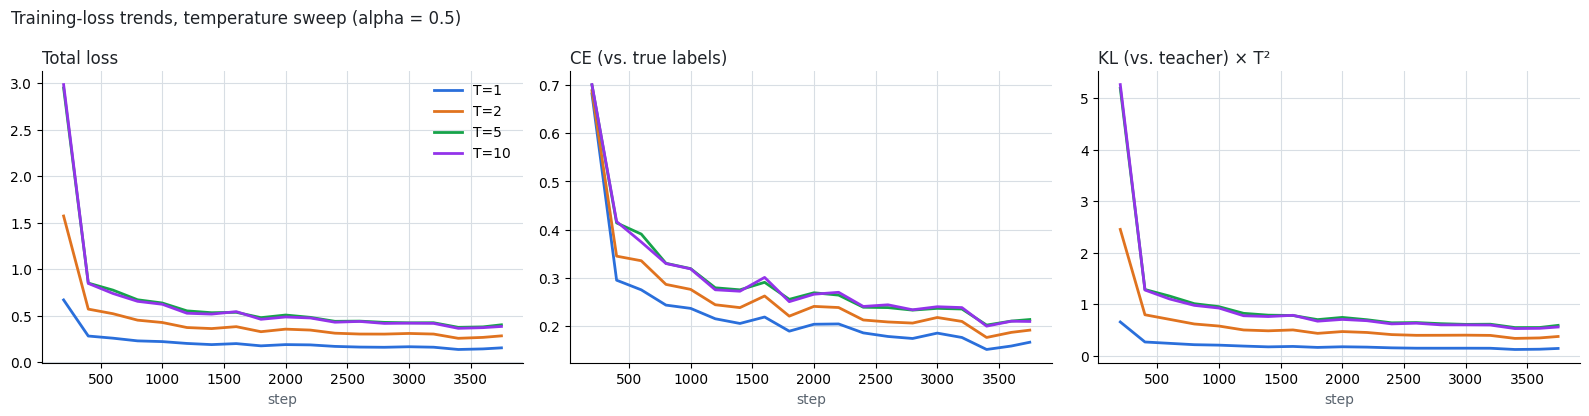

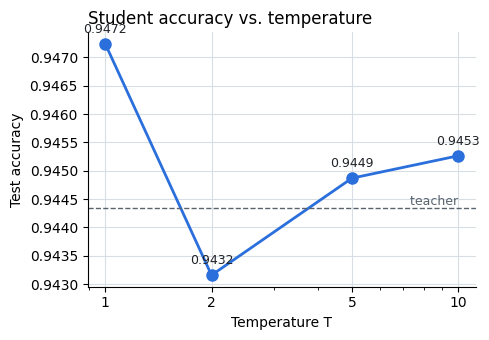

In [20]:
sample = RUNS[f"T{BEST_T}_a{ALPHA_SWEEP_T}"]["history"]
print(f"Sample training log, run T={BEST_T}, alpha={ALPHA_SWEEP_T}:")
display(sample.round(4))

INK, MUTED, GRID = "#1f2328", "#59636e", "#d8dee4"
SERIES = ["#2a6fdb", "#e0731f", "#16a34a", "#9333ea"]   # fixed order, one per temperature
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True)
for ax, key, title in zip(axes, ["loss", "ce", "kl"], ["Total loss", "CE (vs. true labels)", "KL (vs. teacher)" + (" × T²" if KD_T2_SCALING else "")]):
    for c, T in zip(SERIES, TEMPERATURES):
        h = RUNS[f"T{T}_a{ALPHA_SWEEP_T}"]["history"]
        ax.plot(h["step"], h[key], color=c, lw=2, label=f"T={T}")
    ax.set_title(title, color=INK, loc="left"); ax.set_xlabel("step", color=MUTED)
    ax.grid(color=GRID, lw=0.8); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle(f"Training-loss trends, temperature sweep (alpha = {ALPHA_SWEEP_T})", x=0.01, ha="left", color=INK)
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/loss_trends.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(t_sweep["T"], t_sweep["Test accuracy"], marker="o", ms=8, lw=2, color=SERIES[0])
for x, y in zip(t_sweep["T"], t_sweep["Test accuracy"]): ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", color=INK, fontsize=9)
ax.axhline(teacher_res["acc"], color=MUTED, ls="--", lw=1); ax.text(10, teacher_res["acc"], " teacher", va="bottom", ha="right", color=MUTED, fontsize=9)
ax.set_xscale("log"); ax.set_xticks(TEMPERATURES); ax.set_xticklabels(TEMPERATURES)
ax.set_xlabel("Temperature T"); ax.set_ylabel("Test accuracy"); ax.set_title("Student accuracy vs. temperature", loc="left")
ax.grid(color=GRID, lw=0.8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Item 3: Loss-weighting sweep: T fixed at best, α ∈ {0.25, 0.5, 0.75}
Three **fresh** students. The α = 0.5 run is retrained here instead of reused, as the assignment asks. Because the seed is the same, it should closely match the temperature-sweep result, which works as a reproducibility check.

In [21]:
for a in ALPHAS:
    name = f"alphaSweep_T{BEST_T}_a{a}"
    if name not in RUNS: RUNS[name] = train_student(BEST_T, a, name)

a_sweep = pd.DataFrame([{"T": BEST_T, "alpha": a, "Test accuracy": RUNS[f"alphaSweep_T{BEST_T}_a{a}"]["acc"]} for a in ALPHAS])
print(a_sweep.to_markdown(index=False, floatfmt=".4f"))
best_run_name = max(RUNS, key=lambda k: RUNS[k]["acc"])
BEST = RUNS[best_run_name]
print(f"\nBest student overall: {best_run_name} (T={BEST['T']}, alpha={BEST['alpha']}) acc={BEST['acc']:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== alphaSweep_T1_a0.25: T=1, alpha=0.25, steps=3750 ===
step   200/3750 | loss 0.6626 | CE 0.6813 | KL 0.6564 | lr 4.44e-05 | 19s
step   400/3750 | loss 0.2741 | CE 0.2949 | KL 0.2672 | lr 4.75e-05 | 38s
step   600/3750 | loss 0.2505 | CE 0.2765 | KL 0.2418 | lr 4.47e-05 | 57s
step   800/3750 | loss 0.2241 | CE 0.2448 | KL 0.2171 | lr 4.18e-05 | 76s
step  1000/3750 | loss 0.2160 | CE 0.2398 | KL 0.2081 | lr 3.90e-05 | 96s
step  1200/3750 | loss 0.1956 | CE 0.2157 | KL 0.1888 | lr 3.62e-05 | 115s
step  1400/3750 | loss 0.1828 | CE 0.2064 | KL 0.1749 | lr 3.33e-05 | 134s
step  1600/3750 | loss 0.1905 | CE 0.2195 | KL 0.1809 | lr 3.05e-05 | 153s
step  1800/3750 | loss 0.1709 | CE 0.1920 | KL 0.1639 | lr 2.77e-05 | 172s
step  2000/3750 | loss 0.1820 | CE 0.2037 | KL 0.1748 | lr 2.48e-05 | 191s
step  2200/3750 | loss 0.1775 | CE 0.2055 | KL 0.1682 | lr 2.20e-05 | 210s
step  2400/3750 | loss 0.1620 | CE 0.1867 | KL 0.1538 | lr 1.91e-05 | 229s
step  2600/3750 | loss 0.1562 | CE 0.1802 | KL 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

→ alphaSweep_T1_a0.25: test acc = 0.9457  (train 6.0 min)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (5 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== alphaSweep_T1_a0.75: T=1, alpha=0.75, steps=3750 ===
step   200/3750 | loss 0.6762 | CE 0.6824 | KL 0.6574 | lr 4.44e-05 | 19s
step   400/3750 | loss 0.2891 | CE 0.2959 | KL 0.2687 | lr 4.75e-05 | 38s
step   600/3750 | loss 0.2693 | CE 0.2777 | KL 0.2439 | lr 4.47e-05 | 57s
step   800/3750 | loss 0.2356 | CE 0.2425 | KL 0.2152 | lr 4.18e-05 | 76s
step  1000/3750 | loss 0.2288 | CE 0.2364 | KL 0.2060 | lr 3.90e-05 | 96s
step  1200/3750 | loss 0.2127 | CE 0.2195 | KL 0.1922 | lr 3.62e-05 | 115s
step  1400/3750 | loss 0.1980 | CE 0.2060 | KL 0.1739 | lr 3.33e-05 | 134s
step  1600/3750 | loss 0.2097 | CE 0.2192 | KL 0.1813 | lr 3.05e-05 | 153s
step  1800/3750 | loss 0.1845 | CE 0.1914 | KL 0.1637 | lr 2.77e-05 | 172s
step  2000/3750 | loss 0.2005 | CE 0.2080 | KL 0.1777 | lr 2.48e-05 | 191s
step  2200/3750 | loss 0.1943 | CE 0.2034 | KL 0.1669 | lr 2.20e-05 | 210s
step  2400/3750 | loss 0.1776 | CE 0.1856 | KL 0.1536 | lr 1.91e-05 | 230s
step  2600/3750 | loss 0.1697 | CE 0.1775 | KL 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

→ alphaSweep_T1_a0.75: test acc = 0.9457  (train 6.0 min)
|      T |   alpha |   Test accuracy |
|-------:|--------:|----------------:|
| 1.0000 |  0.2500 |          0.9457 |
| 1.0000 |  0.5000 |          0.9472 |
| 1.0000 |  0.7500 |          0.9457 |

Best student overall: T1_a0.5 (T=1, alpha=0.5) acc=0.9472


## Item 1: Separate comparison tables
*Item 1 says to keep the two parts apart: the LLM table above covers the base vs GPTQ model, and the table below covers the BERT teacher vs the DistilBERT student. The four models never go in one accuracy table.*

### Table HW11.2: Distillation comparison on AG News (same test set, same GPU)

In [22]:
def row(name, r):
    return {"Configuration": name, "Accuracy": r["acc"], "p50 / p95 latency (ms)": f'{r["p50"]:.2f} / {r["p95"]:.2f}',
            "Peak memory (GB)": r["peak_GB"], "Size on disk (MB)": r["size_MB"],
            "Params (M)": r["params_M"], f"Test-set inference time (s, bs={EVAL_BS})": r["total_s"]}
t2 = pd.DataFrame([row("BERT teacher", teacher_res),
                   row(f"DistilBERT student (T={BEST['T']}, α={BEST['alpha']})", BEST)])
print(f"GPU: {HARDWARE['gpu']} | latency = single example, bs=1, max_len={MAX_LEN}")
print(t2.to_markdown(index=False, floatfmt=".4f"))
print(f"\nAccuracy retained: {100*BEST['acc']/teacher_res['acc']:.2f}% | size: {BEST['size_MB']/teacher_res['size_MB']:.2f}x | "
      f"p50 speed-up: {teacher_res['p50']/BEST['p50']:.2f}x | test-set throughput speed-up: {teacher_res['total_s']/BEST['total_s']:.2f}x")
json.dump({"teacher": {k: v for k, v in teacher_res.items() if k not in ("preds", "logits")},
           "runs": {k: {kk: vv for kk, vv in v.items() if kk not in ("preds", "logits", "history")} for k, v in RUNS.items()},
           "best_T": BEST_T, "best_run": best_run_name, "hardware": HARDWARE},
          open(f"{WORK_DIR}/part2_results.json", "w"), indent=2, default=str)

GPU: Tesla T4 | latency = single example, bs=1, max_len=128
| Configuration                   |   Accuracy | p50 / p95 latency (ms)   |   Peak memory (GB) |   Size on disk (MB) |   Params (M) |   Test-set inference time (s, bs=128) |
|:--------------------------------|-----------:|:-------------------------|-------------------:|--------------------:|-------------:|--------------------------------------:|
| BERT teacher                    |     0.9443 | 9.44 / 13.89             |             1.0025 |            417.6758 |     109.4853 |                               12.3657 |
| DistilBERT student (T=1, α=0.5) |     0.9472 | 4.41 / 7.52              |             1.6444 |            255.4309 |      66.9565 |                                6.4828 |

Accuracy retained: 100.31% | size: 0.61x | p50 speed-up: 2.14x | test-set throughput speed-up: 1.91x


## Item 4: Where the compression hurts: per-class accuracy

In [23]:
pc = pd.DataFrame({"Teacher": teacher_res["per_class"], "Student": BEST["per_class"]})
pc["Δ (student − teacher)"] = pc["Student"] - pc["Teacher"]
print(pc.to_markdown(floatfmt=".4f"))
WORST = pc["Δ (student − teacher)"].idxmin(); wk = CLASS_NAMES.index(WORST)
print(f"\nClass that degrades most: {WORST} ({pc.loc[WORST, 'Δ (student − teacher)']:+.4f})")

tp, sp = teacher_res["preds"], BEST["preds"]
mask = (test_labels == wk) & (tp == wk) & (sp != wk)
cand = np.where(mask)[0]
print(f"{len(cand)} '{WORST}' test examples: teacher right, student wrong\n")
s_prob = F.softmax(BEST["logits"], -1).numpy()
rng = np.random.default_rng(SEED)
for i in rng.choice(cand, size=min(5, len(cand)), replace=False):
    print(f"[test #{i}] true={WORST} | student → {CLASS_NAMES[sp[i]]} (p={s_prob[i, sp[i]]:.2f})")
    print("   ", ag["test"][int(i)]["text"], "\n")

# confusion: where do the student's errors on this class go?
print("Student mistakes on", WORST, "→", pd.Series([CLASS_NAMES[p] for p in sp[(test_labels == wk) & (sp != wk)]]).value_counts().to_dict())

|          |   Teacher |   Student |   Δ (student − teacher) |
|:---------|----------:|----------:|------------------------:|
| World    |    0.9489 |    0.9511 |                  0.0021 |
| Sports   |    0.9884 |    0.9911 |                  0.0026 |
| Business |    0.9137 |    0.9132 |                 -0.0005 |
| Sci/Tech |    0.9263 |    0.9337 |                  0.0074 |

Class that degrades most: Business (-0.0005)
44 'Business' test examples: teacher right, student wrong

[test #7599] true=Business | student → Sci/Tech (p=0.68)
    EBay gets into rentals EBay plans to buy the apartment and home rental service Rent.com for \$415 million, adding to its already exhaustive breadth of offerings. 

[test #5392] true=Business | student → Sci/Tech (p=0.73)
    Cisco Systems 1st-Quarter Earnings Rise (Reuters) Reuters - Cisco Systems Inc., the biggest maker\of equipment that directs data over the Internet, on Tuesday\said quarterly earnings rose 29 percent on rising demand for\its network

Per-class result: no class degrades meaningfully. The student matches or beats the teacher on World, Sports and Sci/Tech, and Business drops the most, but only by 0.05 points (91.37% → 91.32%). Business is also the weakest class for both models.
What the five examples have in common: they are business stories about technology companies or technical topics: eBay buying Rent.com, Cisco's quarterly earnings, Microsoft's antitrust settlement with Novell, and an energy-policy report. The student is drawn to the company names and technical words ("Internet", "networking gear", "nuclear power", "greenhouse gas"), while the financial framing (acquisition, earnings, lawsuit settlement) goes unnoticed. The odd one out, the Heathrow strike story, went to World for the same reason: the location outweighed the labour/economic angle. Most of the student's Business mistakes go to Sci/Tech (127 of 165, vs 33 to World). With half the layers, the student has less capacity to settle stories that sit between two topics.


GPTQ compressed the existing OPT-125m without retraining. It halved disk size (239 → 119 MB) at the cost of a 17% perplexity increase (23.69 → 27.72), but peak GPU memory didn't change (1.37 GB). With only the PyTorch fallback kernel available on the T4, generation was about 2.5× slower (p50 436 → 1083 ms). Distillation trained a smaller 6-layer architecture instead. The DistilBERT student kept 100.3% of the BERT teacher's accuracy, with 2.14× lower single-example p50 latency (9.44 → 4.41 ms), 1.91× faster full test-set inference and 0.61× the disk size (418 → 255 MB). The cost was seven training runs plus a one-time teacher-logit extraction. We don't compare the two accuracy numbers directly, because the tasks and metrics differ. For a latency-bound deployment I would try distillation first, since removing layers cuts compute on every request with no special kernels needed. For a memory-bound deployment I would try GPTQ first, since it shrinks weight storage with no retraining (and the two can be combined).

---
### Reproducibility record

In [24]:
print(json.dumps({"student": STUDENT_NAME, "SEED": SEED, "HP_ID": HP_ID, "base_llm": BASE_MODEL_ID, "base_sha": BASE_SHA,
                  "teacher_dir": TEACHER_DIR, "student_ckpt": STUDENT_ID, "max_len": MAX_LEN, "train_bs": TRAIN_BS,
                  "lr": LR, "epochs": EPOCHS, "train_subset": TRAIN_SUBSET, "kd_T2_scaling": KD_T2_SCALING,
                  "best_T": BEST_T, "best_run": best_run_name, "hardware": HARDWARE}, indent=2))

{
  "student": "Your Name",
  "SEED": 30000,
  "HP_ID": 0,
  "base_llm": "facebook/opt-125m",
  "base_sha": "27dcfa74d334bc871f3234de431e71c6eeba5dd6",
  "teacher_dir": "/content/teacher_extract/teacher_model",
  "student_ckpt": "distilbert-base-uncased",
  "max_len": 128,
  "train_bs": 32,
  "lr": 5e-05,
  "epochs": 1,
  "train_subset": null,
  "kd_T2_scaling": true,
  "best_T": 1,
  "best_run": "T1_a0.5",
  "hardware": {
    "gpu": "Tesla T4",
    "gpu_mem_GB": 15.6,
    "torch": "2.14.1+cu130",
    "transformers": "5.24.1",
    "cuda": "13.0",
    "python": "3.13.16"
  }
}


peak memory was measured right after training in the same process, so it includes leftover training allocations. Its weights alone are 0.61× the teacher's (67M vs 109M parameters).